In [41]:
data_dir = Path('data_repo/Human Kidney Cancer')
deconv_dir = Path('data_deconvolution/Human Kidney Cancer')

In [3]:
patient_id='PD47171'

In [4]:
# Read ST data
adata_st = sc.read(data_dir/'visium_merge_inter_upload.h5ad')
adata_st.var_names_make_unique()

# Extract patient data
adata_st = kidneycancer.extract_st_patient_data(adata_st, 'PD47171')

In [34]:
adata_st.shape

(2048, 991)

In [5]:
# preprocessing for ST data
GraphST.preprocess(adata_st)

# build graph
GraphST.construct_interaction(adata_st)
GraphST.add_contrastive_label(adata_st)

In [6]:
adata_st

AnnData object with n_obs × n_vars = 2048 × 36601
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'donor_id', 'region'
    var: 'feature_types', 'genome', 'SYMBOL', 'mt', 'n_cells_by_counts-6800STDY12499411', 'mean_counts-6800STDY12499411', 'log1p_mean_counts-6800STDY12499411', 'pct_dropout_by_counts-6800STDY12499411', 'total_counts-6800STDY12499411', 'log1p_total_counts-6800STDY12499411', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'sample_colors', 'spatial', 'hvg', 'log1p'
    obsm: 'spatial', 'distance_matrix', 'graph_neigh', 'adj', 'label_CSL'

In [7]:
# read scRNA data
adata_sc = sc.read(data_dir / 'RCC_upload_final_raw_counts.h5ad')
adata_sc.var_names_make_unique()

adata_sc = kidneycancer.extract_sc_patient_data(adata_sc, patient_id)

In [35]:
adata_sc.shape

(36110, 991)

In [8]:
# Preprocessing for scRNA data
GraphST.preprocess(adata_sc)

In [9]:
adata_sc

AnnData object with n_obs × n_vars = 36110 × 19736
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'patient', 'percent.mt', 'summaryDescription', 'annotation', 'region', 'broad_type'
    var: 'name', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'annotation_colors', 'broad_type_colors', 'region_colors', 'summaryDescription_colors', 'hvg', 'log1p'
    obsm: 'X_pca', 'X_umap'

In [10]:
adata_st

AnnData object with n_obs × n_vars = 2048 × 36601
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'donor_id', 'region'
    var: 'feature_types', 'genome', 'SYMBOL', 'mt', 'n_cells_by_counts-6800STDY12499411', 'mean_counts-6800STDY12499411', 'log1p_mean_counts-6800STDY12499411', 'pct_dropout_by_counts-6800STDY12499411', 'total_counts-6800STDY12499411', 'log1p_total_counts-6800STDY12499411', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'sample_colors', 'spatial', 'hvg', 'log1p'
    obsm: 'spatial', 'distance_matrix', 'graph_neigh', 'adj', 'label_CSL'

In [11]:
adata_st.var

,feature_types,genome,SYMBOL,mt,n_cells_by_counts-6800STDY12499411,mean_counts-6800STDY12499411,log1p_mean_counts-6800STDY12499411,pct_dropout_by_counts-6800STDY12499411,total_counts-6800STDY12499411,log1p_total_counts-6800STDY12499411,highly_variable,highly_variable_rank,means,variances,variances_norm,mean,std
ENSEMBL,,,,,,,,,,,,,,,,,
ENSG00000243485,Gene Expression,GRCh38,MIR1302-2HG,False,0,0.000000,0.000000,100.000000,0.0,0.000000,False,NaN,0.000000,0.000000,0.000000,0.000000,1.000000
ENSG00000237613,Gene Expression,GRCh38,FAM138A,False,0,0.000000,0.000000,100.000000,0.0,0.000000,False,NaN,0.000000,0.000000,0.000000,0.000000,1.000000
ENSG00000186092,Gene Expression,GRCh38,OR4F5,False,0,0.000000,0.000000,100.000000,0.0,0.000000,False,NaN,0.000000,0.000000,0.000000,0.000000,1.000000
ENSG00000238009,Gene Expression,GRCh38,AL627309.1,False,6,0.002930,0.002925,99.707031,6.0,1.945910,False,NaN,0.002930,0.002923,0.961346,0.001484,0.028469
ENSG00000239945,Gene Expression,GRCh38,AL627309.3,False,0,0.000000,0.000000,100.000000,0.0,0.000000,False,NaN,0.000000,0.000000,0.000000,0.000000,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ENSG00000277836,Gene Expression,GRCh38,AC141272.1,False,0,0.000000,0.000000,100.000000,0.0,0.000000,False,NaN,0.000000,0.000000,0.000000,0.000000,1.000000
ENSG00000278633,Gene Expression,GRCh38,AC023491.2,False,0,0.000000,0.000000,100.000000,0.0,0.000000,False,NaN,0.000000,0.000000,0.000000,0.000000,1.000000
ENSG00000276017,Gene Expression,GRCh38,AC007325.1,False,1,0.000488,0.000488,99.951172,1.0,0.693147,False,NaN,0.000488,0.000488,0.999727,0.000360,0.016298


In [12]:
adata_st.var = adata_st.var.reset_index().set_index('SYMBOL')

/opt/conda/envs/GraphST/lib/python3.8/site-packages/anndata/_core/anndata.py:788: UserWarning: 
AnnData expects .var.index to contain strings, but got values like:
    ['MIR1302-2HG', 'FAM138A', 'OR4F5', 'AL627309.1', 'AL627309.3']

    Inferred to be: categorical

  value_idx = self._prep_dim_index(value.index, attr)


In [13]:
adata_st.var

,ENSEMBL,feature_types,genome,mt,n_cells_by_counts-6800STDY12499411,mean_counts-6800STDY12499411,log1p_mean_counts-6800STDY12499411,pct_dropout_by_counts-6800STDY12499411,total_counts-6800STDY12499411,log1p_total_counts-6800STDY12499411,highly_variable,highly_variable_rank,means,variances,variances_norm,mean,std
SYMBOL,,,,,,,,,,,,,,,,,
MIR1302-2HG,ENSG00000243485,Gene Expression,GRCh38,False,0,0.000000,0.000000,100.000000,0.0,0.000000,False,NaN,0.000000,0.000000,0.000000,0.000000,1.000000
FAM138A,ENSG00000237613,Gene Expression,GRCh38,False,0,0.000000,0.000000,100.000000,0.0,0.000000,False,NaN,0.000000,0.000000,0.000000,0.000000,1.000000
OR4F5,ENSG00000186092,Gene Expression,GRCh38,False,0,0.000000,0.000000,100.000000,0.0,0.000000,False,NaN,0.000000,0.000000,0.000000,0.000000,1.000000
AL627309.1,ENSG00000238009,Gene Expression,GRCh38,False,6,0.002930,0.002925,99.707031,6.0,1.945910,False,NaN,0.002930,0.002923,0.961346,0.001484,0.028469
AL627309.3,ENSG00000239945,Gene Expression,GRCh38,False,0,0.000000,0.000000,100.000000,0.0,0.000000,False,NaN,0.000000,0.000000,0.000000,0.000000,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
AC141272.1,ENSG00000277836,Gene Expression,GRCh38,False,0,0.000000,0.000000,100.000000,0.0,0.000000,False,NaN,0.000000,0.000000,0.000000,0.000000,1.000000
AC023491.2,ENSG00000278633,Gene Expression,GRCh38,False,0,0.000000,0.000000,100.000000,0.0,0.000000,False,NaN,0.000000,0.000000,0.000000,0.000000,1.000000
AC007325.1,ENSG00000276017,Gene Expression,GRCh38,False,1,0.000488,0.000488,99.951172,1.0,0.693147,False,NaN,0.000488,0.000488,0.999727,0.000360,0.016298


In [14]:
adata_sc.var

,name,highly_variable,highly_variable_rank,means,variances,variances_norm,mean,std
FO538757.3,FO538757.3,False,NaN,0.000000,0.000000,0.000000,0.000000,1.000000
FO538757.2,FO538757.2,False,NaN,0.151288,0.166953,0.836943,0.191975,0.499412
AP006222.2,AP006222.2,False,NaN,0.001329,0.001494,0.942714,0.001758,0.050461
RP5-857K21.4,RP5-857K21.4,False,NaN,0.000000,0.000000,0.000000,0.000000,1.000000
RP11-206L10.9,RP11-206L10.9,False,NaN,0.004708,0.005406,0.908967,0.006093,0.093694
...,...,...,...,...,...,...,...,...
BACH1-IT2,BACH1-IT2,False,NaN,0.000000,0.000000,0.000000,0.000000,1.000000
AP000282.2,AP000282.2,False,NaN,0.000000,0.000000,0.000000,0.000000,1.000000
LINC01436,LINC01436,False,NaN,0.000000,0.000000,0.000000,0.000000,1.000000
CRYAA,CRYAA,False,NaN,0.000000,0.000000,0.000000,0.000000,1.000000


In [15]:
from GraphST.preprocess import filter_with_overlap_gene

adata_st, adata_sc = filter_with_overlap_gene(adata_st, adata_sc)

/opt/conda/envs/GraphST/lib/python3.8/site-packages/GraphST/preprocess.py:34: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns["overlap_genes"] = genes
/opt/conda/envs/GraphST/lib/python3.8/site-packages/GraphST/preprocess.py:35: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata_sc.uns["overlap_genes"] = genes


Number of overlap genes: 991


In [1]:
adata_st.var

NameError: name 'adata_sc' is not defined

In [ ]:
adata_sc.var

In [16]:
adata_st

View of AnnData object with n_obs × n_vars = 2048 × 991
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'donor_id', 'region'
    var: 'ENSEMBL', 'feature_types', 'genome', 'mt', 'n_cells_by_counts-6800STDY12499411', 'mean_counts-6800STDY12499411', 'log1p_mean_counts-6800STDY12499411', 'pct_dropout_by_counts-6800STDY12499411', 'total_counts-6800STDY12499411', 'log1p_total_counts-6800STDY12499411', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'sample_colors', 'spatial', 'hvg', 'log1p', 'overlap_genes'
    obsm: 'spatial', 'distance_matrix', 'graph_neigh', 'adj', 'label_CSL'

In [17]:
adata_sc

View of AnnData object with n_obs × n_vars = 36110 × 991
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'patient', 'percent.mt', 'summaryDescription', 'annotation', 'region', 'broad_type'
    var: 'name', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'annotation_colors', 'broad_type_colors', 'region_colors', 'summaryDescription_colors', 'hvg', 'log1p', 'overlap_genes'
    obsm: 'X_pca', 'X_umap'

In [18]:
# get features
GraphST.get_feature(adata_st)

In [19]:
import  torch

# Run device
device = torch.device('cuda:1' if torch.cuda.is_available() else 'cpu')

# Train model
model = GraphST.GraphST(adata_st, adata_sc, epochs=1200, random_seed=50, device=device, deconvolution=True)
adata_st, adata_sc = model.train_map()

Begin to train ST data...


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1200/1200 [00:29<00:00, 40.05it/s]


Optimization finished for ST data!
Begin to train scRNA data...


100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1200/1200 [00:11<00:00, 106.59it/s]


Optimization finished for cell representation learning!
Begin to learn mapping matrix...


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1200/1200 [00:32<00:00, 37.15it/s]


Mapping matrix learning finished!


In [23]:
adata_sc.obs['cell_type'] = adata_sc.obs['broad_type']

In [24]:
# Project cells into spatial space
from GraphST.utils import project_cell_to_spot
project_cell_to_spot(adata_st, adata_sc, retain_percent=0.01)

In [25]:
adata_st

AnnData object with n_obs × n_vars = 2048 × 991
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'donor_id', 'region', 'B-cell', 'EC', 'Epi_PT', 'Epi_non-PT', 'Fibro', 'Mast', 'Myeloid', 'NK', 'Plasma', 'RCC', 'T-cell', 'pDC'
    var: 'ENSEMBL', 'feature_types', 'genome', 'mt', 'n_cells_by_counts-6800STDY12499411', 'mean_counts-6800STDY12499411', 'log1p_mean_counts-6800STDY12499411', 'pct_dropout_by_counts-6800STDY12499411', 'total_counts-6800STDY12499411', 'log1p_total_counts-6800STDY12499411', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'sample_colors', 'spatial', 'hvg', 'log1p', 'overlap_genes'
    obsm: 'spatial', 'distance_matrix', 'graph_neigh', 'adj', 'label_CSL', 'feat', 'feat_a', 'emb_sp', '

In [27]:
# get all cell types
cell_types = sorted(adata_sc.obs['cell_type'].unique())
cell_types

['B-cell',
 'EC',
 'Epi_PT',
 'Epi_non-PT',
 'Fibro',
 'Mast',
 'Myeloid',
 'NK',
 'Plasma',
 'RCC',
 'T-cell',
 'pDC']

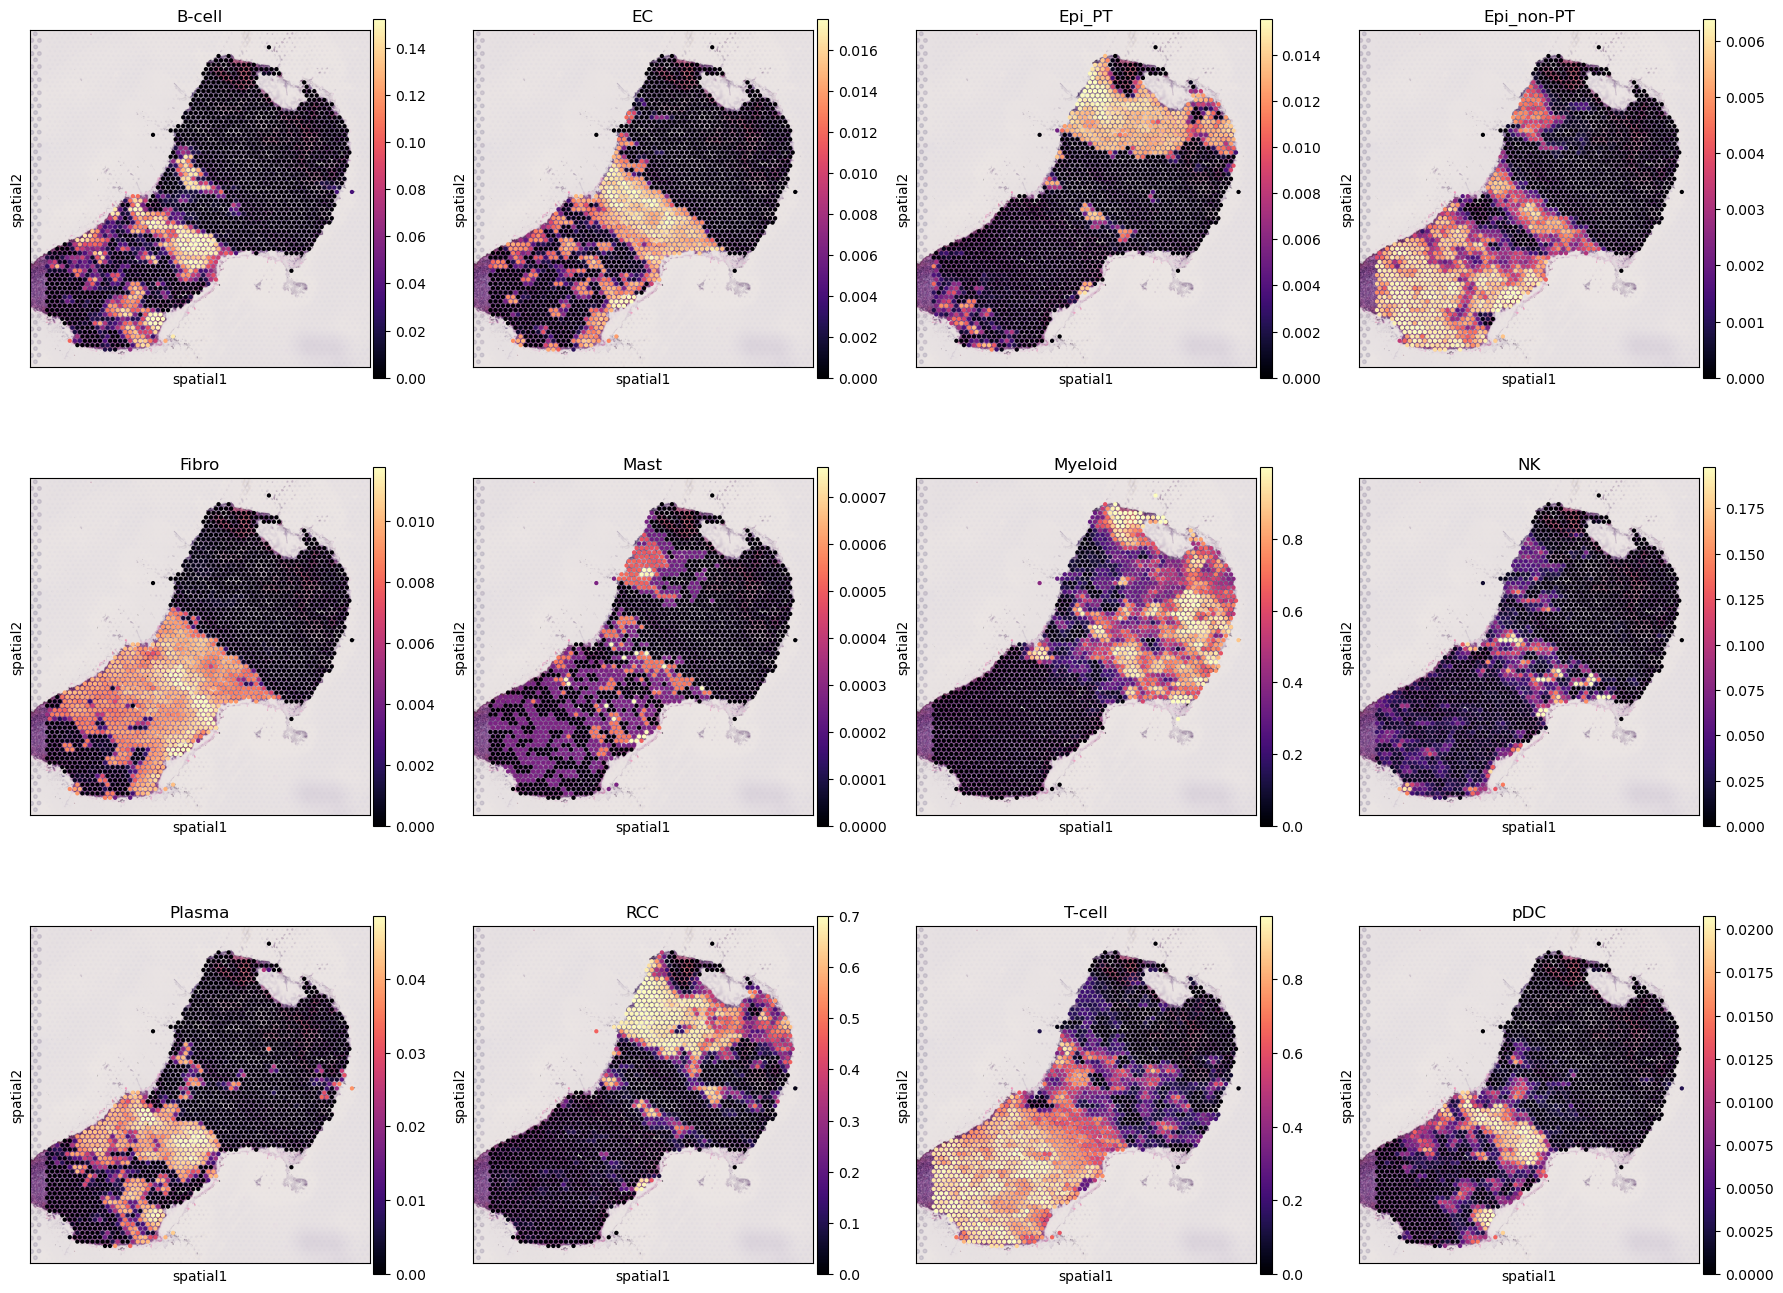

In [31]:
# Visualization of spatial distribution of scRNA-seq data
import matplotlib as mpl
import matplotlib.pyplot as plt

with mpl.rc_context({'axes.facecolor': 'black',
                    'figure.figsize': [4.5, 5]}):
    sc.pl.spatial(adata_st, cmap='magma',
                     # selected cell types
                     color=cell_types,
                     ncols=4, size=1.3,
                     img_key='hires',
                     # limit color scale at 99.2% quantile of cell abundance
                     vmin=0, vmax='p99.2',
                     show=True
                 )

In [33]:
adata_st.obs

,in_tissue,array_row,array_col,sample,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,...,Epi_PT,Epi_non-PT,Fibro,Mast,Myeloid,NK,Plasma,RCC,T-cell,pDC
spot_id,,,,,,,,,,,,,,,,,,,,,
6800STDY12499411_AAACAAGTATCTCCCA-1,1,50,102,6800STDY12499411,4778,8.471987,14815.0,9.603463,27.046912,35.227810,...,0.000000,0.000000,0.000000,0.000000,0.955600,0.000000,0.000000,0.005671,0.038729,0.000000
6800STDY12499411_AAACACCAATAACTGC-1,1,59,19,6800STDY12499411,1536,7.337588,2822.0,7.945555,27.250177,36.463501,...,0.006377,0.005815,0.000273,0.000272,0.000000,0.007665,0.003536,0.009876,0.927704,0.000545
6800STDY12499411_AAACATGGTGAGAGGA-1,1,62,0,6800STDY12499411,2243,7.716015,4582.0,8.430109,28.000873,35.050196,...,0.001643,0.005530,0.000000,0.000000,0.000000,0.020692,0.000000,0.003266,0.968869,0.000000
6800STDY12499411_AAACCGGGTAGGTACC-1,1,42,28,6800STDY12499411,2555,7.846199,4903.0,8.497807,19.620640,28.696716,...,0.000000,0.004205,0.010061,0.000543,0.002742,0.008781,0.042876,0.000545,0.764998,0.017207
6800STDY12499411_AAACCGTTCGTCCAGG-1,1,52,42,6800STDY12499411,1277,7.153052,2113.0,7.656337,22.432560,32.465689,...,0.000000,0.004453,0.009816,0.000549,0.000820,0.004670,0.044279,0.002467,0.766725,0.015719
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6800STDY12499411_TTGTTCAGTGTGCTAC-1,1,24,64,6800STDY12499411,3235,8.082093,8386.0,9.034438,25.518722,36.358216,...,0.013727,0.002852,0.000000,0.000259,0.292430,0.009486,0.000000,0.675862,0.005385,0.000000
6800STDY12499411_TTGTTGTGTGTCAAGA-1,1,31,77,6800STDY12499411,4374,8.383662,12266.0,9.414668,22.215881,31.664764,...,0.000000,0.000000,0.000000,0.000000,0.905304,0.008181,0.000000,0.076973,0.009541,0.000000
6800STDY12499411_TTGTTTCACATCCAGG-1,1,58,42,6800STDY12499411,1328,7.192182,2317.0,7.748460,23.910229,34.570565,...,0.000000,0.006159,0.009762,0.000558,0.019260,0.005765,0.003005,0.024311,0.919932,0.002454


In [36]:
adata_st.uns['cell_types'] = cell_types

In [38]:
adata_st.uns['cell_types']

['B-cell',
 'EC',
 'Epi_PT',
 'Epi_non-PT',
 'Fibro',
 'Mast',
 'Myeloid',
 'NK',
 'Plasma',
 'RCC',
 'T-cell',
 'pDC']

In [43]:
adata_st.write_h5ad(deconv_dir / f'visium_merge_inter_upload_{patient_id}.h5ad')